# MODELING

> - We'll predict how many units customers will buy each week. We'll include all categories & combine online and offline purchases.
> - Each week runs from Monday to Sunday. We'll use completed weeks to predict all of the next 13 weeks at once.
> - We chose 13 weeks because it is close to three months of planning. It does not mean purchases repeat every 13 weeks.
> - We'll compare the historical mean, ARIMA, linear regression & a small random forest.
> - We have 104 complete weeks. The feature table has more rows because the same target week can appear in forecasts made on different dates.
> - We already looked at the full data in EDA and saw the last quarter in an earlier model run. This is a comparison using old data, not a new test on unseen data.


In [4]:
# Loading the weekly purchases and the saved features.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

weekly_target = pd.read_csv("../data/processed/weekly_target.csv", parse_dates=["week_end"])
weekly_target = weekly_target.set_index("week_end")
weekly_units = weekly_target["weekly_units"]
weekly_units = weekly_units.sort_index()
weekly_units = weekly_units.asfreq("W-SUN")
feature_table = pd.read_csv("../data/processed/features.csv",
parse_dates=["origin_week_end", "forecast_week_end"])
print(f"Complete weeks: {len(weekly_units)} | Feature rows: {len(feature_table)}")
print(f"Missing weekly totals: {weekly_units.isna().sum()}")

Complete weeks: 104 | Feature rows: 1313
Missing weekly totals: 0


### PLANNING THE TIME SPLITS

> - We'll keep the last 13 weeks aside for a later comparison.
> - Before that, we'll check each model on three separate periods of 13 weeks. These checks are called validation.
> - For each check, the model learns from earlier weeks & predicts the next 13 weeks.
> - After each check, we'll add those completed weeks to the history before starting the next check.
> - The code will calculate the first training size and the dates. We are choosing three checks to compare more than one period while keeping about a year of history for the first check.
> - This is a reasonable split plan for our small dataset. It is not proof that these training sizes are the best possible ones.

In [6]:
# Calculating the time splits from the number of complete weeks.
horizon_weeks = 13
validation_rounds = 3
development_weeks = weekly_units.iloc[:-horizon_weeks]
test_origin = development_weeks.index[-1]
first_train_weeks = len(development_weeks) - (validation_rounds * horizon_weeks)

fold_rows = []
for round_number in range(validation_rounds):
    training_weeks = first_train_weeks + (round_number * horizon_weeks)
    cutoff = development_weeks.index[training_weeks - 1]
    validation_start = development_weeks.index[training_weeks]
    validation_end = development_weeks.index[training_weeks + horizon_weeks - 1]
    fold_rows.append({"cutoff": cutoff,"training_weeks": training_weeks,
    "validation_start": validation_start,"validation_end": validation_end})
fold_plan = pd.DataFrame(fold_rows)
validation_origins = fold_plan["cutoff"]
display(fold_plan)
print(f"First training size: {len(development_weeks)} - {validation_rounds} * {horizon_weeks} = {first_train_weeks}")
print(f"Last-period cutoff: {test_origin.date()}")

,cutoff,training_weeks,validation_start,validation_end
0,2023-12-31,52,2024-01-07,2024-03-31
1,2024-03-31,65,2024-04-07,2024-06-30
2,2024-06-30,78,2024-07-07,2024-09-29


First training size: 91 - 3 * 13 = 52
Last-period cutoff: 2024-09-29


### MODELS WE WILL TRY

> - The historical mean predicts the average of all completed weeks. It gives us a simple forecast to compare against.
> - ARIMA uses the weekly purchase series directly. We'll try two small versions to check different ways of using past purchases and past errors.
> - Linear regression checks whether simple linear links between our inputs and future purchases are useful.
> - Random forest can learn more complex links between the same inputs and future purchases.
> - We'll keep the smaller forest from the earlier work. The larger forest learned the training examples too closely and made larger errors on later weeks; this is called overfitting.
> - We will not add SARIMA yet. We have not shown a clear repeating seasonal pattern, and the first training period has only about one year of weekly history.

In [7]:
# Choosing a small set of models and their input columns.
feature_columns = ["horizon_weeks", "forecast_month",
"units_latest_week", "mean_units_4weeks"]
arima_orders = {"ARIMA(1,0,0)": (1, 0, 0),"ARIMA(0,1,1)": (0, 1, 1)}
small_forest = RandomForestRegressor(n_estimators=200, max_depth=3, min_samples_leaf=20,
random_state=42, n_jobs=-1)
ml_models = {"Linear regression": LinearRegression(),"Small forest": small_forest}
print(f"Missing input values: {feature_table[feature_columns].isna().sum().sum()}")

Missing input values: 0


### CHECKING THE MODELS FAIRLY

> - At each cutoff, we'll use purchases from that date and earlier. Purchases from the next 13 weeks must stay unknown while we make the forecasts.
> - ARIMA & the historical mean use the completed weekly totals. The regression models use the four input columns.
> - A training row can be used only if its target week has already happened by the cutoff.
> - Each model predicts the same next 13 weeks. We will not give it actual purchases from inside that window as we move through the forecast.
> - The latest-week units & four-week mean stay the same within each forecast window. The forecast month and number of weeks ahead can change.

In [8]:
# Making all 13 forecasts from each validation cutoff.
validation_predictions = []
for origin in validation_origins:
    history = weekly_units.loc[:origin]
    train = feature_table[feature_table["forecast_week_end"] <= origin]
    block = feature_table[feature_table["origin_week_end"] == origin]
    block = block.sort_values("horizon_weeks")
    predictions = {"Historical mean": np.repeat(history.mean(), horizon_weeks)}
    for name, order in arima_orders.items():
        fitted = ARIMA(history, order=order).fit()
        predictions[name] = fitted.forecast(steps=horizon_weeks).to_numpy()
        print(f"{origin.date()} | {name} | converged: {fitted.mle_retvals['converged']}")
    for name, template in ml_models.items():
        x_train = train[feature_columns]
        y_train = train["target_units"]
        model = clone(template)
        model.fit(x_train, y_train)
        predictions[name] = model.predict(block[feature_columns])
    for name, prediction in predictions.items():
        validation_predictions.append({
            "model": name, "cutoff": origin,
            "forecast_week_end": block["forecast_week_end"].to_numpy(),
            "actual_units": block["target_units"].to_numpy(),
            "predicted_units": prediction})

2023-12-31 | ARIMA(1,0,0) | converged: True
2023-12-31 | ARIMA(0,1,1) | converged: True
2024-03-31 | ARIMA(1,0,0) | converged: True
2024-03-31 | ARIMA(0,1,1) | converged: True
2024-06-30 | ARIMA(1,0,0) | converged: True
2024-06-30 | ARIMA(0,1,1) | converged: True


### COMPARING THE VALIDATION ERRORS

> - We'll measure each model's errors in each of the three checks, then take the average for that model.
> - We'll choose the model with the lowest average MAE. Each check covers the same number of weeks.
> - We'll also look at each check separately. A model may do well in one period and badly in another.
> - A very small difference between models does not show that one will always be better.

In [9]:
# Measuring each forecast block and comparing the three-round averages.
validation_scores = []
for result in validation_predictions:
    y = result["actual_units"]
    prediction = result["predicted_units"]
    validation_scores.append({
        "model": result["model"], "cutoff": result["cutoff"],
        "mae": mean_absolute_error(y, prediction),
        "rmse": np.sqrt(mean_squared_error(y, prediction)),
        "wape": np.abs(y - prediction).sum() / y.sum() * 100})
validation_scores = pd.DataFrame(validation_scores)
validation_summary = validation_scores.groupby("model")[["mae", "rmse", "wape"]].mean()
validation_summary = validation_summary.sort_values("mae")
selected_name = validation_summary.index[0]
display(validation_summary.round(2))
fold_mae = validation_scores.pivot(index="cutoff", columns="model", values="mae")
display(fold_mae.round(2))
print(f"Model chosen using validation MAE: {selected_name}")

,mae,rmse,wape
model,,,
Small forest,12.63,15.16,9.31
Linear regression,12.67,15.26,9.33
Historical mean,12.92,15.53,9.51
"ARIMA(0,1,1)",12.92,15.53,9.51
"ARIMA(1,0,0)",12.95,15.59,9.54


model,"ARIMA(0,1,1)","ARIMA(1,0,0)",Historical mean,Linear regression,Small forest
cutoff,,,,,
2023-12-31,11.69,11.73,11.69,11.21,11.21
2024-03-31,11.06,11.17,11.06,10.77,10.51
2024-06-30,16.00,15.96,16.00,16.03,16.18


Model chosen using validation MAE: Small forest


### CHECKING THE LAST 13 WEEKS

> - We'll train the chosen model again using only purchases known before the last 13 weeks begin. We'll keep the same model settings.
> - We'll predict those 13 weeks & compare the errors with the historical mean.
> - We already saw this last period in the earlier model run, so it is not a new unseen test.
> - We'll report what happened without changing settings to improve this result. We would need new actual purchases for a fresh test.

In [10]:
# Training the chosen model before the last 13-week period.
history = weekly_units.loc[:test_origin]
train = feature_table[feature_table["forecast_week_end"] <= test_origin]
test = feature_table[feature_table["origin_week_end"] == test_origin]
test = test.sort_values("horizon_weeks")
mean_prediction = np.repeat(history.mean(), horizon_weeks)
if selected_name in arima_orders:
    fitted = ARIMA(history, order=arima_orders[selected_name]).fit()
    test_prediction = fitted.forecast(steps=horizon_weeks).to_numpy()
elif selected_name in ml_models:
    x_train = train[feature_columns]
    y_train = train["target_units"]
    selected_model = clone(ml_models[selected_name])
    selected_model.fit(x_train, y_train)
    test_prediction = selected_model.predict(test[feature_columns])
else:
    test_prediction = mean_prediction
test_forecast = pd.DataFrame({
    "forecast_week_end": test["forecast_week_end"].to_numpy(),
    "actual_units": test["target_units"].to_numpy(),
    selected_name: test_prediction,
    "Historical mean": mean_prediction
})
print(f"Past weeks: {len(history)} | Training rows: {len(train)} | Forecast weeks: {len(test)}")

Past weeks: 91 | Training rows: 1053 | Forecast weeks: 13


,mae,rmse,wape
model,,,
Small forest,16.91,19.51,12.26
Historical mean,13.10,16.02,9.50


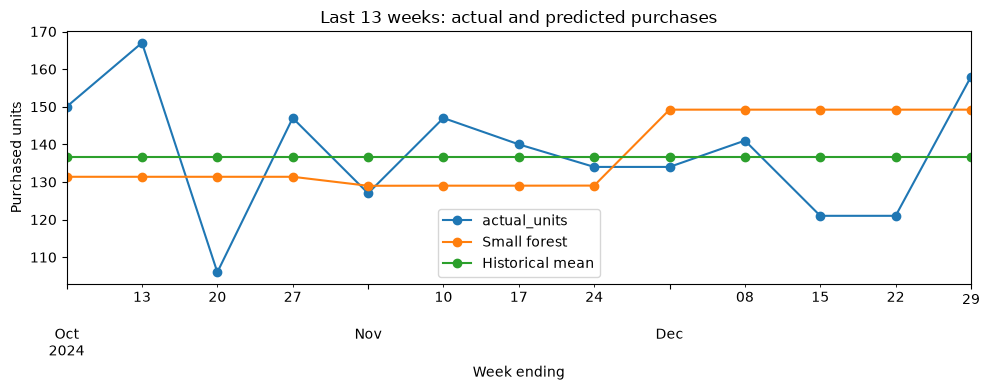

In [11]:
# Comparing the last-period forecasts with actual purchases.
test_results = []
y_test = test_forecast["actual_units"].to_numpy()
for name in test_forecast.columns[2:]:
    prediction = test_forecast[name].to_numpy()
    test_results.append({
        "model": name,
        "mae": mean_absolute_error(y_test, prediction),
        "rmse": np.sqrt(mean_squared_error(y_test, prediction)),
        "wape": np.abs(y_test - prediction).sum() / y_test.sum() * 100})
test_results = pd.DataFrame(test_results)
test_results = test_results.set_index("model")
display(test_results.round(2))
plot_data = test_forecast.set_index("forecast_week_end")
ax = plot_data.plot(marker="o", figsize=(10, 4))
ax.set_title("Last 13 weeks: actual and predicted purchases")
ax.set_xlabel("Week ending")
ax.set_ylabel("Purchased units")
plt.tight_layout()
plt.show()

### EXAMPLE FORECAST

> - We'll train the model chosen by validation on all completed weeks, keeping its settings the same.
> - The data ends on 29 December 2024. We'll predict the next 13 weeks, ending 5 January through 30 March 2025.
> - These are examples from the old dataset, not forecasts for today. We have no actual purchases for these weeks to measure their errors.

In [12]:
# Making example forecasts after the dataset's last completed week.
latest_origin = weekly_units.index.max()
all_train = feature_table[feature_table["forecast_week_end"] <= latest_origin]
future = feature_table[feature_table["origin_week_end"] == latest_origin]
future = future.sort_values("horizon_weeks")
future_mean = np.repeat(weekly_units.mean(), horizon_weeks)
if selected_name in arima_orders:
    fitted = ARIMA(weekly_units, order=arima_orders[selected_name]).fit()
    future_prediction = fitted.forecast(steps=horizon_weeks).to_numpy()
elif selected_name in ml_models:
    x_train = all_train[feature_columns]
    y_train = all_train["target_units"]
    forecast_model = clone(ml_models[selected_name])
    forecast_model.fit(x_train, y_train)
    future_prediction = forecast_model.predict(future[feature_columns])
else:
    future_prediction = future_mean
forecast = future[["origin_week_end", "forecast_week_end", "horizon_weeks"]].copy()
forecast = forecast.reset_index(drop=True)
forecast[selected_name] = future_prediction
forecast["Historical mean"] = future_mean
print(f"Forecast cutoff: {latest_origin.date()} | Chosen model: {selected_name}")
display(forecast.round({selected_name: 2, "Historical mean": 2}))

Forecast cutoff: 2024-12-29 | Chosen model: Small forest


,origin_week_end,forecast_week_end,horizon_weeks,Small forest,Historical mean
0,2024-12-29,2025-01-05,1,130.33,136.8
1,2024-12-29,2025-01-12,2,130.33,136.8
2,2024-12-29,2025-01-19,3,130.38,136.8
3,2024-12-29,2025-01-26,4,130.45,136.8
4,2024-12-29,2025-02-02,5,131.50,136.8
5,2024-12-29,2025-02-09,6,131.59,136.8
6,2024-12-29,2025-02-16,7,131.71,136.8
7,2024-12-29,2025-02-23,8,131.87,136.8
8,2024-12-29,2025-03-02,9,133.21,136.8
9,2024-12-29,2025-03-09,10,133.15,136.8


In [14]:
import os
import pickle
import platform
import sklearn

model_bundle = {
    "model_name": selected_name,
    "model": forecast_model,
    "historical_mean_units": float(weekly_units.mean()),
    "feature_columns": feature_columns,
    "horizon_weeks": horizon_weeks,
    "week_frequency": "W-SUN",
    "trained_through": str(latest_origin.date()),
    "target": "Weekly purchased units across all categories and channels",
    "model_role": "Comparison demo; mean performed better in the last period",
    "versions": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__
    }
}

os.makedirs("../models", exist_ok=True)
model_path = "../models/demand_forecast.pkl"

# Saving the fitted model and its details.
with open(model_path, "wb") as file:
    pickle.dump(model_bundle, file)

# Loading it again to check the predictions.
with open(model_path, "rb") as file:
    loaded_bundle = pickle.load(file)

x_check = future[loaded_bundle["feature_columns"]]
loaded_prediction = loaded_bundle["model"].predict(x_check)

print(f"Saved to: {model_path}")
print(f"Same predictions after loading: {np.allclose(future_prediction, loaded_prediction)}")

Saved to: ../models/demand_forecast.pkl
Same predictions after loading: True


# MODELING SUMMARY

> - I compared the historical mean, ARIMA, linear regression & a small random forest using three 13-week validation rounds.
> - The forest had the lowest average validation MAE, but the historical mean did better on the last 13 weeks: 13.10 versus 16.91 units. The forest did not show a clear improvement.
> - I saved the final fitted forest with the historical mean & input details using pickle. Loading it gave the same predictions.
> - I had already seen the last period during earlier work, so I need new actual purchases for a fresh check of forecast accuracy.